# Relaxation at zero and ultralow field

At zero and ultralow field the scalar couplings, not the Zeeman interaction,
set the eigenstates. In PF₆⁻ the phosphorus spin and the total spin `K` of the
six fluorines couple to a total angular momentum `F`, and the spectrum has its
lines near multiples of `J`. A sample polarised at a high field and carried
down adiabatically arrives in these eigenstates, with populations set by their
order in energy. This guide follows those populations and the lines:

- `spynach.pathways.energy_levels` gives the eigenstates of the isotropic
  Hamiltonian, grouped into levels `|K, F, M>`;
- `Levels.adiabatic` gives their populations after an adiabatic transfer from a
  polarising field;
- `relaxation_pathways(..., basis=levels)` gives the relaxation between the
  populations, by mechanism and with expressions, which `plot_pathways` draws as
  a chord diagram;
- `relaxation_pathways(..., basis=levels.lines(...))` gives the width `R2` of
  every line.

Read the [relaxation pathways guide](relaxation-pathways.ipynb) first. The
companion notebook is
[`notebooks/zulf-pathways.ipynb`](zulf-pathways.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/zulf-pathways.ipynb)).
The PF₆⁻ parameters are those of the contributed script
`user_ml/ZULF_PF6_1D.m`. The browser playground runs this analysis with
tunable parameters, for PF₆⁻
([`try.html#ex-ulf-pf6`](https://ajerschow.github.io/spynach/try.html#ex-ulf-pf6))
and for ¹¹BF₄⁻
([`try.html#ex-ulf-bf4`](https://ajerschow.github.io/spynach/try.html#ex-ulf-bf4)).

Every Python block is executed by `tests/docs/`, in order and in one
namespace. The expressions need SymPy (`pip install -e ".[symbolic]"`).

*Generated from [`docs/zulf-pathways.md`](../zulf-pathways.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Energy levels](#Energy-levels)
2. [Adiabatic transfer from a polarising field](#Adiabatic-transfer-from-a-polarising-field)
3. [Relaxation between level populations](#Relaxation-between-level-populations)
4. [The chord diagram](#The-chord-diagram)
5. [Widths of the lines](#Widths-of-the-lines)
6. [Tetrafluoroborate](#Tetrafluoroborate)
7. [Checks](#Checks)
8. [Options and limits](#Options-and-limits)

## Energy levels

The spin system is defined as usual, at the ultralow field: here 2.7 µT, with
`1J(PF) = 710` Hz and the fluorines at the corners of an octahedron of 1.6 Å.
`energy_levels` diagonalises the isotropic lab-frame Hamiltonian, the Zeeman
interaction with the isotropic shifts plus the isotropic couplings, with no
secular approximation, in Hilbert space:

In [1]:
import numpy as np
from scipy.linalg import expm

import spynach
from spynach.pathways import energy_levels
from spynach.plotting import plot_pathways, plot_time_series

directions = [[0, 0, 0], [-1, 0, 0], [1, 0, 0], [0, -1, 0], [0, 1, 0], [0, 0, -1], [0, 0, 1]]
pf6 = spynach.create(
    {"isotopes": ["31P"] + ["19F"] * 6, "magnet": 2.7e-6},
    {"coupling": {"scalar": [[0] + [710.0] * 6] + [[0] * 7 for _ in range(6)]},
     "coordinates": (1.6 * np.array(directions, dtype=float)).tolist()},
)
levels = energy_levels(pf6)
print(f"{len(levels)} levels, degeneracies {sorted({level.degeneracy for level in levels})}")
for level in [levels[0], levels[8], levels[14], levels[-1]]:
    print(f"  {level.label:12s} E/2pi = {level.energy / (2 * np.pi):9.2f} Hz, {level.degeneracy} states")

32 levels, degeneracies [1, 5, 9]
  3,7/2,+7/2   E/2pi =    717.08 Hz, 1 states
  3,5/2,+5/2   E/2pi =  -1712.72 Hz, 1 states
  2,5/2,+5/2   E/2pi =    470.29 Hz, 5 states
  0,1/2,-1/2   E/2pi =     23.29 Hz, 5 states


The eigenstates are sorted into blocks of what the Hamiltonian conserves: the
total projection `M`, and the total spin `K` of each group of equivalent spins
(the six fluorines here). A level is a set of degenerate eigenstates of one
block, labelled `K,F,M`. The degeneracies are the numbers of copies of each
multiplet of six spins ½, which have the same energy: 1 for `K = 3`, 5 for
`K = 2` and `K = 0`, 9 for `K = 1`. `F` is the total angular momentum of the zero-field level that the
level connects to as the field goes to zero, since levels of one block keep
their order in energy. At zero field it is exact; at 2.7 µT it is a label.
The levels are ordered by `K`, `F` and `M`, highest first.

## Adiabatic transfer from a polarising field

`levels.adiabatic(from_field)` returns the population of every level after an
adiabatic transfer from thermal equilibrium at `from_field`, here 1 T, in the
high-temperature approximation. Populations are deviations from the uniform
`1/N`, per state, at 298 K unless `temperature` is given. Within a block the
levels share every symmetry and do not cross, so the n-th state by energy at
1 T becomes the n-th state by energy at 2.7 µT:

In [2]:
populations = levels.adiabatic(from_field=1.0)
manifolds = {}  # (K, F) -> level numbers
for k, level in enumerate(levels):
    manifolds.setdefault(level.label.rsplit(",", 1)[0], []).append(k)
scale = np.abs(populations).max()
print(f"largest population per state {scale:.3g}; by manifold, relative to it, from M = +F down:")
for name, ks in manifolds.items():
    print(f"  K,F = {name}: " + " ".join(f"{populations[k] / scale:+.2f}" for k in ks))

largest population per state 1.62e-07; by manifold, relative to it, from M = +F down:
  K,F = 3,7/2: +1.00 +0.69 +0.38 +0.07 -0.24 -0.56 -0.87 -1.00
  K,F = 3,5/2: +0.87 +0.56 +0.24 -0.07 -0.38 -0.69
  K,F = 2,5/2: +0.69 +0.38 +0.07 -0.24 -0.56 -0.69
  K,F = 2,3/2: +0.56 +0.24 -0.07 -0.38
  K,F = 1,3/2: +0.38 +0.07 -0.24 -0.38
  K,F = 1,1/2: +0.24 -0.07
  K,F = 0,1/2: +0.07 -0.07


For PF₆⁻ this reproduces, to 0.4%, the state after an adiabatic drop that came
with `ZULF_PF6_1D.m` (`user_ml/rho_adiabatic_drop.csv`, 3431 nonzero
coefficients in the `sphten-liouv` basis); `tests/unit/test_levels.py` makes
the comparison.

## Relaxation between level populations

With `basis=levels`, `relaxation_pathways` builds the relaxation matrix between
the level populations, the normalised projectors onto the levels, instead of
between product operators. All transition frequencies at 2.7 µT are far below
`1 / tau_c`, so every spectral density is `J(0) = tau_c`. Then two populations
are coupled only through the parts of the relaxation that oscillate at the same
frequency, so they are secular without a further approximation. The 19F
shielding anisotropy is left out with `mechanisms`: it relaxes as the square of
the field and is negligible here. The 31P has none in an octahedron.
`resolve="interaction"` separates the P–F dipoles, the F–F dipoles (cis and
trans, `b_FF1` and `b_FF2`) and their cross-correlations:

In [3]:
pathways = spynach.relaxation_pathways(pf6, basis=levels, tau_c=65e-12, mechanisms=("DD",), resolve="interaction")
print(pathways.classes, f"{len(pathways.links())} pathways")
for link in pathways.links()[:2]:
    a, b = pathways.labels[link.source], pathways.labels[link.target]
    print(f"  {a} <-> {b}: {link.rate:.3f} s^-1")
    for cls in link.signature:
        print(f"    {cls}: {link.expressions[cls]}")

['DD(FF)', 'DD(PF)', "DD(FF)/DD(FF')", 'DD(FF)/DD(PF)', "DD(PF)/DD(PF')"] 324 pathways
  2,5/2,-5/2 <-> 1,3/2,-1/2: -0.717 s^-1
    DD(FF): -0.274864*b_FF1**2*J(0) - 1.09946*b_FF2**2*J(0)
    DD(PF): -0.579228*b_PF**2*J(0)
    DD(FF)/DD(FF'): -0.0229054*b_FF1**2*J(0) - 0.0229054*b_FF1*b_FF2*J(0) - 0.0572634*b_FF2**2*J(0)
    DD(FF)/DD(PF): -0.65564*b_FF1*b_PF*J(0) - 0.65564*b_FF2*b_PF*J(0)
    DD(PF)/DD(PF'): -0.115846*b_PF**2*J(0)
  2,5/2,+5/2 <-> 1,3/2,+1/2: -0.698 s^-1
    DD(FF): -0.296932*b_FF1**2*J(0) - 1.18773*b_FF2**2*J(0)
    DD(PF): -0.496474*b_PF**2*J(0)
    DD(FF)/DD(FF'): -0.0247443*b_FF1**2*J(0) - 0.0247443*b_FF1*b_FF2*J(0) - 0.0618608*b_FF2**2*J(0)
    DD(FF)/DD(PF): -0.630897*b_FF1*b_PF*J(0) - 0.630897*b_FF2*b_PF*J(0)
    DD(PF)/DD(PF'): -0.0992948*b_PF**2*J(0)


`d<P_i>/dt = -sum_j Gamma[i, j] <P_j>` for the normalised projectors `P_i`,
whose expectations are the populations per state times the square root of the
degeneracy. The total population is conserved, and `Gamma` has one zero
eigenvalue. The others are the relaxation rates of the population pattern, from
1.3 to 5.5 s⁻¹. Starting from the transferred populations, summed over each
`(K, F)` manifold:

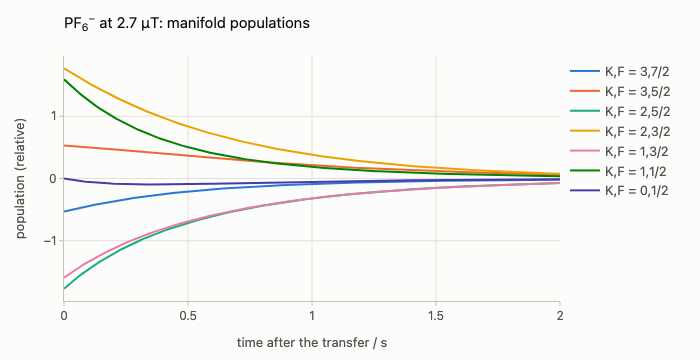

In [4]:
gamma = pathways.rate_matrix()
d = np.array([level.degeneracy for level in levels])
times = np.linspace(0, 2, 201)
evolution = np.array([expm(-gamma * t) @ (populations * np.sqrt(d)) for t in times]) * np.sqrt(d)
fig = plot_time_series(times, [evolution[:, ks].sum(axis=1) / scale for ks in manifolds.values()],
                       names=[f"K,F = {name}" for name in manifolds], xlabel="time after the transfer / s",
                       ylabel="population (relative)", title="PF<sub>6</sub><sup>−</sup> at 2.7 µT: manifold populations")
fig.update_layout(legend={"orientation": "v", "x": 1.01, "xanchor": "left", "y": 1, "yanchor": "top"}, margin={"r": 140})

## The chord diagram

The population pathways as a chord diagram: one arc per level, one ribbon per
class and pathway (`split=True`), and the pathways weaker than 40% of the
strongest hidden. Hovering over a level shows its energy and degeneracy and its
auto-relaxation rate:

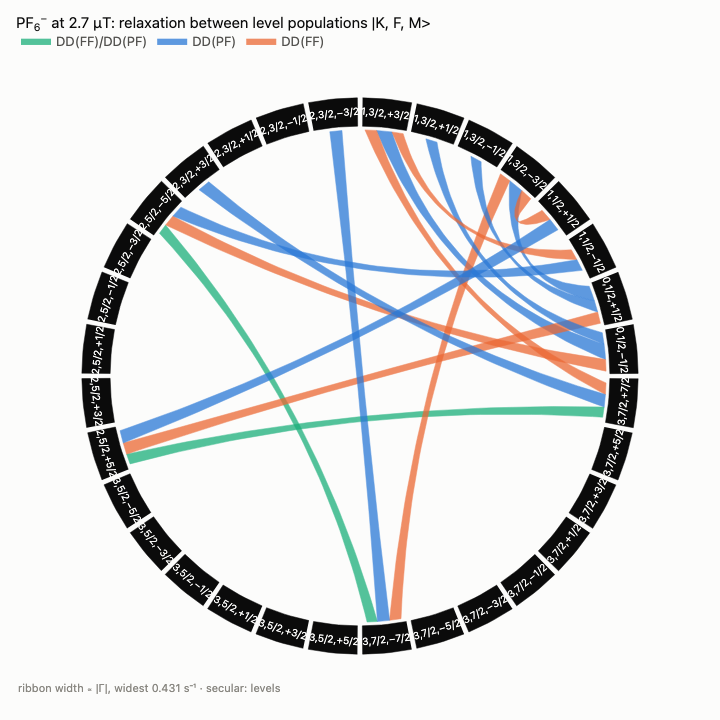

In [5]:
offdiagonal = np.abs(gamma - np.diag(np.diag(gamma)))
plot_pathways(pathways, split=True, min_rate=0.4 * offdiagonal.max(),
              title="PF<sub>6</sub><sup>−</sup> at 2.7 µT: relaxation between level populations |K, F, M>")

## Widths of the lines

`levels.lines(detection)` groups the coherences of the detected magnetisation,
`sum_k gamma_k I_k` along `z` (the field, as a ZULF magnetometer records it) or
`x`, into lines by frequency. Lines below `min_weight` of the strongest are
left out. With these coherences as the basis, the diagonal of the relaxation
matrix is the width `R2` of each line, again by mechanism. Lines at different
frequencies are not secular to each other, so the off-diagonal elements are
zero:

In [6]:
lines = levels.lines("z")
widths = spynach.relaxation_pathways(pf6, basis=lines, tau_c=65e-12, mechanisms=("DD",), resolve="interaction")
R2 = np.diag(widths.rate_matrix())
for line, r2 in zip(lines, R2):
    print(f"  {line.frequency:8.2f} Hz  weight {line.weight:.3f}  R2 {r2:.3f} s^-1  {line.label}")

   1046.07 Hz  weight 1.000  R2 3.310 s^-1  1,3/2,-1/2 – 1,1/2,-1/2
   1087.10 Hz  weight 0.926  R2 3.317 s^-1  1,3/2,+1/2 – 1,1/2,+1/2
   1738.72 Hz  weight 0.402  R2 3.074 s^-1  2,5/2,-3/2 – 2,3/2,-3/2
   1763.71 Hz  weight 0.586  R2 2.963 s^-1  2,5/2,-1/2 – 2,3/2,-1/2
   1788.35 Hz  weight 0.570  R2 2.962 s^-1  2,5/2,+1/2 – 2,3/2,+1/2
   1812.65 Hz  weight 0.370  R2 3.075 s^-1  2,5/2,+3/2 – 2,3/2,+3/2
   2441.36 Hz  weight 0.061  R2 2.741 s^-1  3,7/2,-5/2 – 3,5/2,-5/2
   2459.22 Hz  weight 0.101  R2 2.741 s^-1  3,7/2,-3/2 – 3,5/2,-3/2
   2476.95 Hz  weight 0.119  R2 2.741 s^-1  3,7/2,-1/2 – 3,5/2,-1/2
   2494.55 Hz  weight 0.117  R2 2.741 s^-1  3,7/2,+1/2 – 3,5/2,+1/2
   2512.03 Hz  weight 0.096  R2 2.741 s^-1  3,7/2,+3/2 – 3,5/2,+3/2
   2529.39 Hz  weight 0.057  R2 2.741 s^-1  3,7/2,+5/2 – 3,5/2,+5/2


At zero field the lines are those of the `J`-spectrum, `(K + 1/2) J`: 1065,
1775 and 2485 Hz. At 2.7 µT each splits by `M`, and their widths run from 2.7
to 3.3 s⁻¹. As stems, with the contribution of each class:

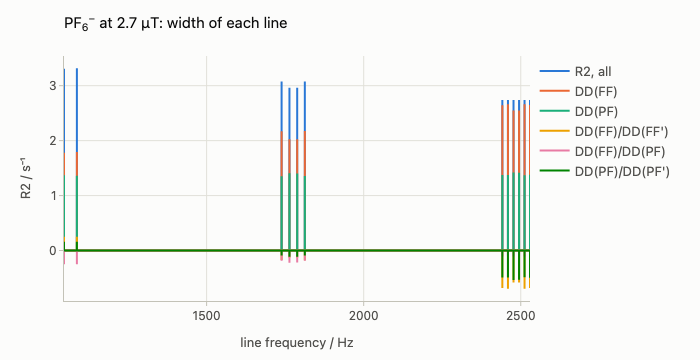

In [7]:
def comb(values):
    """A stem at each line frequency, joined along zero."""
    x = np.repeat(lines.frequencies, 3)
    y = np.zeros_like(x)
    y[1::3] = values
    return x, y


by_class = {cls: np.diag(widths.rate_matrix(cls)) for cls in widths.classes}
axis, total = comb(R2)
fig = plot_time_series(axis, [total] + [comb(v)[1] for v in by_class.values()], names=["R2, all"] + list(by_class),
                       xlabel="line frequency / Hz", ylabel="R2 / s⁻¹", title="PF<sub>6</sub><sup>−</sup> at 2.7 µT: width of each line")
fig.update_layout(legend={"orientation": "v", "x": 1.01, "xanchor": "left", "y": 1, "yanchor": "top"}, margin={"r": 170})

## Tetrafluoroborate

¹¹BF₄⁻ works the same way, with the spin-3/2 boron, a quadrupolar coupling and
`1J(11B,19F)` near 1.1 Hz in dilute solution (up to 4.8 Hz in saturated
solution, depending on the cation). Its sign is not established, and it decides
the order of the levels and so which ones the transfer fills. The coupling
dominates only below some 40 nT:

In [8]:
from spynach.conventions import eeqq2nqi

corners = np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) / np.sqrt(3)
bf4 = spynach.create(
    {"isotopes": ["11B"] + ["19F"] * 4, "magnet": 10e-9},
    {"coupling": {"scalar": [[0] + [1.1] * 4] + [[0] * 5 for _ in range(4)],
                  "matrix": [[eeqq2nqi(100e3, 0.0, 1.5, [0, 0, 0]).tolist()] + [None] * 4] + [[None] * 5 for _ in range(4)]},
     "coordinates": [[0, 0, 0]] + (1.40 * corners).tolist()},
)
bf4_levels = energy_levels(bf4)
bf4_pathways = spynach.relaxation_pathways(bf4, basis=bf4_levels, tau_c=10e-12, mechanisms=("DD", "Q"))
print(f"{len(bf4_levels)} levels; classes {bf4_pathways.classes}")

36 levels; classes ['DD', 'Q', 'DD/DD']


The quadrupole relaxes the boron and the dipoles, through their
cross-correlation `DD/DD`, the coupled states. As in the
[pathways guide](relaxation-pathways.ipynb#Cross-correlations-that-cancel-by-symmetry),
`DD/Q` cancels between the symmetric level populations, by the tetrahedral sum
rule. The playground example `#ex-ulf-bf4` has the field, the coupling and its
sign, the distance, the quadrupolar coupling and the correlation time in its
form.

## Checks

The rates against `spynach.relaxation`, which evaluates the Redfield integral
numerically in the lab frame. For a ³¹P–¹⁹F₂ fragment with shielding
anisotropies, the population and line rates projected from its Redfield
superoperator agree with the eigenbasis rates:

In [9]:
fragment = spynach.create(
    {"isotopes": ["31P", "19F", "19F"], "magnet": 2.7e-6},
    {"zeeman": {"matrix": [None, np.diag([-40.0, -40, 80]).tolist(), np.diag([30.0, 30, -60]).tolist()]},
     "coupling": {"scalar": [[0, 710.0, 710.0], [0, 0, 0], [0, 0, 0]]},
     "coordinates": [[0, 0, 0], [1.6, 0, 0], [-0.4, 1.55, 0]],
     "relaxation": ["redfield"], "rlx_keep": "labframe", "equilibrium": "zero", "tau_c": [[20e-12]]},
)
liouville = spynach.basis(fragment, {"formalism": "sphten-liouv", "approximation": "none"})
R = spynach.relaxation(liouville)
R = R.toarray() if hasattr(R, "toarray") else np.asarray(R)
fragment_levels = energy_levels(fragment)
for basis in (fragment_levels, fragment_levels.lines("z")):
    check = spynach.relaxation_pathways(fragment, basis=basis)
    V = check.states(liouville)
    reference, mine = -(V.conj() @ R @ V.T).real, check.rate_matrix()
    if basis is not fragment_levels:
        reference, mine = np.diag(reference), np.diag(mine)
    print(f"{len(basis)} operators: largest difference {np.abs(mine - reference).max() / np.abs(mine).max():.1e} of the largest rate")

8 operators: largest difference 2.2e-05 of the largest rate
2 operators: largest difference 3.2e-06 of the largest rate


The difference is set by the truncation of the numerical integral
(`tols.rlx_integration`). `tests/unit/test_levels.py` makes the same
comparison for a ¹¹B–¹⁹F pair with a quadrupole, at 3 and 50 µT and at zero
field, for detection along `z` and `x`. It also checks the zero-field energies
`E(F)`, the lines at `(K + 1/2) J`, and the adiabatic transfer against
`user_ml/rho_adiabatic_drop.csv`.

## Options and limits

| call | arguments |
|---|---|
| `energy_levels(spin_system, groups=None)` | `groups`: the spins taken as equivalent, whose total spin labels the blocks (default: same isotope and isotropic shift; a group whose spin the Hamiltonian does not conserve is left out) |
| `levels.adiabatic(from_field=1.0, temperature=298.0)` | populations per state of every level after the transfer (high-temperature deviations) |
| `levels.lines(detection="z", min_weight=1e-3)` | `detection`: `"z"` or `"x"`; lines below `min_weight` of the strongest are left out |
| `relaxation_pathways(spin_system, basis=..., tau_c, mechanisms, resolve)` | `basis`: the levels (populations) or the lines (widths, on the diagonal); `groups`, `ranks`, `max_order`, `max_per_group`, `coherence` and `secular` are not used |

Limits:

- extreme narrowing: every transition frequency must be far below `1 / tau_c`,
  as at zero and ultralow field. Otherwise `relaxation_pathways` raises, and the
  product-operator basis is the one to use;
- each population, and each line, is secular by itself. Levels closer than the
  relaxation rates, near a crossing, and coherences between degenerate levels
  of different blocks are outside this description;
- the adiabatic transfer is ideal. It is exact when the total projection and
  the total spins of the groups are all the symmetries along the field path;
  with another symmetry, levels of one block could cross;
- Hilbert space: up to 4096 states;
- as in the product-operator analysis, rank-2 mechanisms only, without
  dynamic frequency shifts.